In [280]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('transactions_TP2.csv')


In [281]:

#Partie 1
# identifier data types
print("les types: ",df.dtypes)
#catégorielles
cqt_cols=df.select_dtypes(include=['object']).columns.tolist()
print( "type de donnes categorielles :",cqt_cols)
#numeriques
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print( "type de donnes categorielles :",num_cols)
# 5 ligne premier
print("les 5 ligne premier : ",df.head())
print("nombre de column,nombre de ligne: ",df.shape)

les types:  id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object
type de donnes categorielles : ['id_operation', 'id_client', 'canal', 'appareil', 'region', 'international', 'resultat_enquete']
type de donnes categorielles : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'fraude']
les 5 ligne premier :    id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      O

C:\Users\Pc\AppData\Local\Temp\ipykernel_5856\3377208089.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cqt_cols=df.select_dtypes(include=['object']).columns.tolist()


In [282]:
#le pourcentage de valeurs manquantes.
p_v_m=df.isnull().mean()*100
print("pourcentage des valeurs manquants: ",p_v_m)
#le résultat dans un tableau trié du plus grand au plus petit pourcentag
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_count = df.isnull().sum()

missing_df = pd.DataFrame({
    'Nombre_Manquantes': missing_count,
    'Pourcentage_%': missing_percent
}).sort_values(by='Pourcentage_%', ascending=False)


display(missing_df)


pourcentage des valeurs manquants:  id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


,Nombre_Manquantes,Pourcentage_%
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


In [283]:
#id operation
duplicates_count = df.duplicated(subset=['id_operation']).sum()
print(f"(Doublons): {duplicates_count}")

# supprimer les doublons
df = df.drop_duplicates(subset=['id_operation'])
#ile nombre de lignes restantes.
print(f"nombre de lignes restantes: {df.shape[0]}")

(Doublons): 45
nombre de lignes restantes: 3000


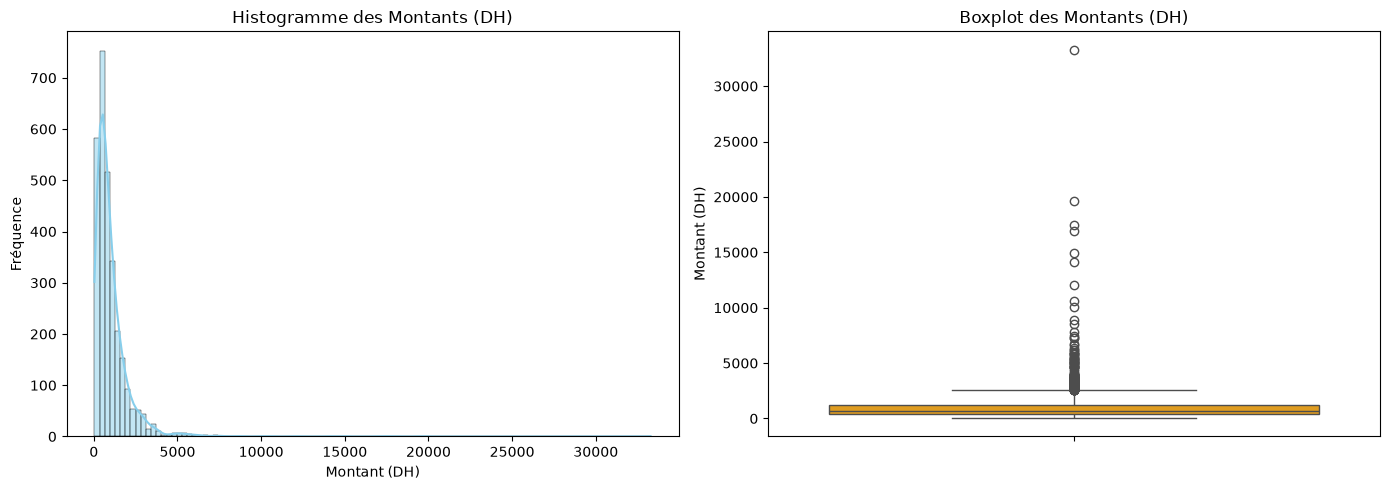

In [284]:
plt.figure(figsize=(14, 5))

# 1. Histogramme du montant
plt.subplot(1, 2, 1)
sns.histplot(df['montant_dh'], kde=True, color='skyblue')
plt.title('Histogramme des Montants (DH)')
plt.xlabel('Montant (DH)')
plt.ylabel('Fréquence')

# 2. Boxplot du montant
plt.subplot(1, 2, 2)
sns.boxplot(y=df['montant_dh'], color='orange')
plt.title('Boxplot des Montants (DH)')
plt.ylabel('Montant (DH)')

plt.tight_layout()
plt.show()
#Réponse : Non, il ne faut pas forcément supprimer les montants extrêmes (outliers).
#​Justification : Dans le cadre de la détection des fraudes, les montants extrêmement élevés ou atypiques peuvent correspondre à de véritables opérations frauduleuses. Les supprimer sans vérification risquerait d'éliminer des signaux d'alerte très importants pour les modèles prédictifs. On ne les supprime que s'il s'agit d'erreurs manifestes de saisie.

Proportion des classes (%) :
 fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


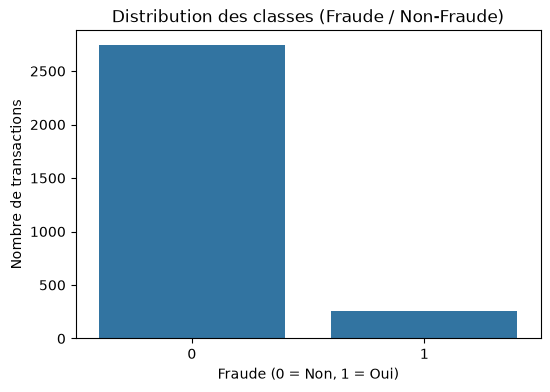

In [285]:
#la proportion de fraudes (fraude = 1)
fraud_counts = df['fraude'].value_counts(normalize=True) * 100
print("Proportion des classes (%) :\n", fraud_counts)
#diagramme
plt.figure(figsize=(6, 4))
sns.countplot(x='fraude', data=df)
plt.title('Distribution des classes (Fraude / Non-Fraude)')
plt.xlabel('Fraude (0 = Non, 1 = Oui)')
plt.ylabel('Nombre de transactions')
plt.show()
#Réponse : Non, le jeu de données est très déséquilibré. Les cas de fraude (fraude = 1) sont extrêmement rares par rapport aux transactions normales (fraude = 0).
#​Pourquoi est-ce important pour préparer les données ?
#Réponse : Un déséquilibre important pousse les algorithmes de Machine Learning à privilégier la classe majoritaire (prédire toujours "non-fraude" donne une haute exactitude globale, mais rate toutes les fraudes). Cela nécessite l'utilisation de techniques de rééchantillonnage (comme Oversampling / Undersampling) et de métriques d'évaluation adaptées (comme le F1-score).

In [286]:
#​Pourquoi ces colonnes (id_operation, id_client) ne doivent pas être incluses dans les variables préparées (X) ?
#​Ce sont des identifiants uniques ou des valeurs aléatoires. Elles n'apportent aucune relation statistique ou logique permettant de prédire une fraude. Les inclure risquerait de provoquer un surapprentissage (overfitting).
#​À quel moment connaît-on le resultat_enquete ?
#​On ne le connaît qu'a posteriori (après coup), c'est-à-dire après que la transaction a eu lieu, qu'elle a été suspectée, et qu'une investigation humaine a été menée

In [287]:
#Partie 2
# 1.
y = df['fraude']

# 2.
X = df.drop(columns=['id_operation', 'id_client', 'resultat_enquete', 'fraude'])

# suces de l'etapes x et y
print(f"Dimensions de X : {X.shape}")
print(f"Dimensions de y : {y.shape}")

# colonnes restant
print("\nColonnes incluses dans X :")
print(X.columns.tolist())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)

Colonnes incluses dans X :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


In [288]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

#taux de fraude
print("--- Proportion de fraude dans y_train (80%) ---")
print((y_train.value_counts(normalize=True) * 100))

print("\n--- Proportion de fraude dans y_test (20%) ---")
print((y_test.value_counts(normalize=True) * 100))

--- Proportion de fraude dans y_train (80%) ---
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

--- Proportion de fraude dans y_test (20%) ---
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [289]:
# Numériques
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Catégorielles
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


C:\Users\Pc\AppData\Local\Temp\ipykernel_5856\1365192982.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [290]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# pipeline numerique
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # تعويض القيم الناقصة بالوسيط (Médiane)
    ('scaler', StandardScaler())                 # توحيد المقاييس (StandardScaler)
])

print("Le pipeline numérique a été construit avec succès !")

Le pipeline numérique a été construit avec succès !


In [291]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# pipeline catégoriel
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # تعويض القيم الناقصة بالقيمة الأكثر تكراراً (Mode)
    ('onehot', OneHotEncoder(handle_unknown='ignore'))     # تحويل الفئات إلى أرقام ثنائية مع تجاهل القيم الجديدة غير المعروفة مستقبلاً
])

print("Le pipeline catégoriel a été construit avec succès !")

Le pipeline catégoriel a été construit avec succès !


In [292]:
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Dimensions de X_train_prepared :", X_train_prepared.shape)
print("Dimensions de X_test_prepared :", X_test_prepared.shape)

C:\Users\Pc\AppData\Local\Temp\ipykernel_5856\1331636037.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


Dimensions de X_train_prepared : (2400, 18)
Dimensions de X_test_prepared : (600, 18)


In [293]:
from sklearn.preprocessing import RobustScaler

# Mise à jour du pipeline numérique pour utiliser RobustScaler au lieu de StandardScalernum
StandardScalernum_pipeline_robust = Pipeline(steps=[
 ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()) # استخدام RobustScaler المقاوم للقيم المتطرفة
])

# Reconstruction du préprocesseur avec RobustScaler
preprocessor_robust = ColumnTransformer(
    transformers=[
        ('num', num_pipeline_robust, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

# Application du nouveau traitement à X_train
X_train_robust = preprocessor_robust.fit_transform(X_train)

print("Le pipeline a été mis à jour avec RobustScaler avec succès !")

Le pipeline a été mis à jour avec RobustScaler avec succès !


In [294]:
# Qu'est-ce qui peut mal se passer si la médiane ou les paramètres de normalisation sont calculés sur toutes les lignes, y compris le groupe de vérification ?
#Réponse : Cela provoque ce qu'on appelle une fuite de données (Data Leakage).
#Justification : Si l'on calcule les paramètres statistiques (comme la médiane, la moyenne ou l'écart-type) sur l'ensemble complet des données avant la division (train/test), les informations du groupe de vérification (X_test) se retrouvent "infiltrées" dans le groupe de référence (X_train). Par conséquent, le modèle aura un aperçu indirect des données qu'il est censé découvrir par la suite. Bien que cela puisse donner artificiellement de bons résultats lors de l'évaluation, le modèle aura un mauvais pouvoir de généralisation et échouera en conditions réelles sur de nouvelles données. C'est pourquoi ces paramètres doivent être calculés uniquement sur le groupe de référence (X_train). 

In [295]:
# Partie 3:
# Calcul des quartiles Q1 et Q3 pour montant_dh sur le groupe de référence (X_train)
Q1 = X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)

# Calcul de l'écart interquartile (IQR)
IQR = Q3 - Q1

print(f"Q1 (25%) : {Q1}")
print(f"Q3 (75%) : {Q3}")
print(f"IQR : {IQR}")
#Que mesure l'IQR ?
# Réponse : L'écart interquartile (\text{IQR} = Q_3 - Q_1) mesure la dispersion statistique de la moitié centrale des données (entre le 25e et le 75e percentile).

Q1 (25%) : 393.095
Q3 (75%) : 1249.8775
IQR : 856.7825


In [296]:
# Calcul des seuils pour les valeurs extrêmes (outliers)
seuil_bas = Q1 - 1.5 * IQR
seuil_haut = Q3 + 1.5 * IQR

# Identifier les lignes concernées par ces valeurs extrêmes dans X_train
outliers = X_train[(X_train['montant_dh'] < seuil_bas) | (X_train['montant_dh'] > seuil_haut)]

print(f"Nombre de lignes concernées par les valeurs extrêmes : {len(outliers)}")
print(f"Seuil bas : {seuil_bas}")
print(f"Seuil haut : {seuil_haut}")

Nombre de lignes concernées par les valeurs extrêmes : 146
Seuil bas : -892.0787499999999
Seuil haut : 2535.05125


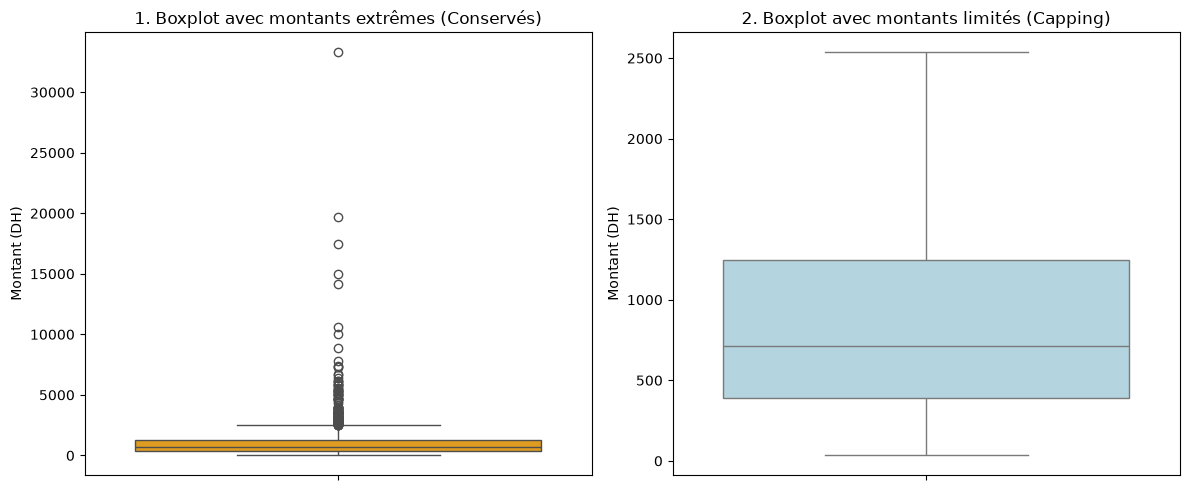

In [297]:


import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#(Capping)
montant_capped = X_train['montant_dh'].copy()
montant_capped = np.clip(montant_capped, seuil_bas, seuil_haut)

#Tracer correctement les deux diagrammes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# Premier graphique (données originales avec valeurs aberrantes)
sns.boxplot(y=X_train['montant_dh'], ax=ax1, color='orange')
ax1.set_title("1. Boxplot avec montants extrêmes (Conservés)")
ax1.set_ylabel("Montant (DH)")

# # Deuxième graphique (données après capping)
sns.boxplot(y=montant_capped, ax=ax2, color='lightblue')
ax2.set_title("2. Boxplot avec montants limités (Capping)")
ax2.set_ylabel("Montant (DH)")

plt.tight_layout()
plt.show()

In [298]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Extraction de la colonne « montant_dh » pour les ensembles d'entraînement et de test sous forme de matrice 2D (comme requis par le scaler)
train_montant = X_train[['montant_dh']]
test_montant = X_test[['montant_dh']]

# 1. MinMaxScaler
min_max_scaler = MinMaxScaler()
train_minmax = min_max_scaler.fit_transform(train_montant)
test_minmax = min_max_scaler.transform(test_montant)

# 2. StandardScaler
std_scaler = StandardScaler()
train_std = std_scaler.fit_transform(train_montant)
test_std = std_scaler.transform(test_montant)

# 3. RobustScaler
rob_scaler = RobustScaler()
train_rob = rob_scaler.fit_transform(train_montant)
test_rob = rob_scaler.transform(test_montant)

print("Les trois transformations ont été appliquées avec succès sur X_train et X_test !")

Les trois transformations ont été appliquées avec succès sur X_train et X_test !


In [299]:
import pandas as pd
import numpy as np

# 1. Sélectionner 3 montants habituels et un montant très élevé pour l'expérience
montants_test = np.array([[100.0], [500.0], [1200.0], [50000.0]])
# 2. Les transformer en utilisant les scalers préalablement entraînés dans la question 18
val_minmax = min_max_scaler.transform(montants_test)
val_std = std_scaler.transform(montants_test)
val_rob = rob_scaler.transform(montants_test)

# 3. Regroupement des résultats dans un tableau structuré (DataFrame)
df_comparaison = pd.DataFrame({
    'Montant Original (DH)': montants_test.flatten(),
    'MinMaxScaler': val_minmax.flatten(),
    'StandardScaler': val_std.flatten(),
    'RobustScaler': val_rob.flatten()
})

# tableau
display(df_comparaison)


c:\Users\Pc\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
c:\Users\Pc\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Pc\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


,Montant Original (DH),MinMaxScaler,StandardScaler,RobustScaler
0,100.0,0.001913,-0.690077,-0.712888
1,500.0,0.013945,-0.394055,-0.246025
2,1200.0,0.035001,0.123983,0.570985
3,50000.0,1.502898,36.238625,57.528264


In [300]:
#Quelle méthode est la plus perturbée par les montants extrêmes ? Réponse : MinMaxScaler et StandardScaler sont les plus perturbées par les montants extrêmes (valeurs aberrantes).
#Justification :MinMaxScaler dépend directement de la valeur maximale (max). Si le maximum est un montant extrêmement élevé, la plage de variation est complètement écrasée, ce qui tasse tous les montants habituels vers de très petites valeurs proches de 0.
# StandardScaler dépend de la moyenne (moyenne) et de l'écart-type (écart-type), lesquels sont fortement augmentés par les valeurs aberrantes. Cela fausse la standardisation des données normales.
# En revanche, RobustScaler utilise la médiane et l'IQR, ce qui la rend insensible à ce montant très élevé et protège la distribution des valeurs habituelles.

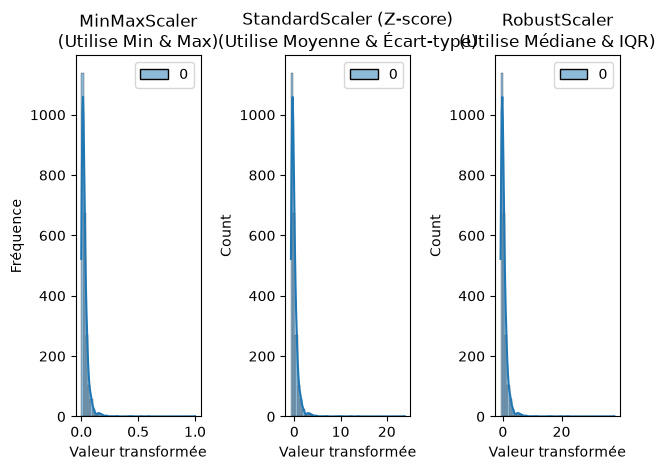

In [301]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tracé des histogrammes pour comparer les trois méthodes après la transformationplt.figure(figsize=(15, 5))

# 1. MinMaxScaler Histogram
plt.subplot(1, 3, 1)
sns.histplot(train_minmax, bins=50, color='blue', kde=True)
plt.title('MinMaxScaler\n(Utilise Min & Max)')
plt.xlabel('Valeur transformée')
plt.ylabel('Fréquence')

# 2. StandardScaler Histogram
plt.subplot(1, 3, 2)
sns.histplot(train_std, bins=50, color='green', kde=True)
plt.title('StandardScaler (Z-score)\n(Utilise Moyenne & Écart-type)')
plt.xlabel('Valeur transformée')

# 3. RobustScaler Histogram
plt.subplot(1, 3, 3)
sns.histplot(train_rob, bins=50, color='orange', kde=True)
plt.title('RobustScaler\n(Utilise Médiane & IQR)')
plt.xlabel('Valeur transformée')

plt.tight_layout()
plt.show()


In [302]:
#Explication des différences entre les histogrammes :
# MinMaxScaler : Compresse toutes les données dans un intervalle borné (généralement entre 0 et 1). Si la distribution contient des valeurs extrêmes, la grande majorité des données habituelles se retrouve tassée sur une toute petite portion de l'axe (proche de 0).
# StandardScaler (Z-score) : Centre les données autour de 0 avec un écart-type de 1. L'histogramme garde une forme similaire à la distribution normale (gaussienne), mais s'étale largement si des valeurs aberrantes font exploser l'écart-type.
# RobustScaler : Centre les données autour de la médiane et utilise l'IQR. L'histogramme est beaucoup moins déformé par les valeurs extrêmes, ce qui préserve la lisibilité et la structure centrale des données habituelles

In [303]:
#Peut-elle dépasser 1 avec MinMaxScaler ?
# Réponse : Oui, une nouvelle valeur peut tout à fait dépasser 1 si elle est supérieure au maximum observé dans le groupe de référence (X_train)
#Vérification avec un exemple numérique :Supposons que dans le groupe de référence (X_train), le montant minimum est \min = 0 et le montant maximum est \max = 1000.
#La formule de transformation de MinMaxScaler est : x-min/max-min
#Si une nouvelle transaction arrive avec un montant x = 1500 (qui dépasse le maximum de référence 1000) :1500-0/1500-0=1.5

In [304]:
# Calcul du nombre de lignes par classe dans l'ensemble d'entraînement (ensemble de référence / y_train)
counts = y_train.value_counts()
print("Nombre de lignes par classe :")
print(counts)

# Calcul du rapport entre la classe non frauduleuse (0) et la classe frauduleuse (1)
ratio = counts[0] / counts[1]
print(f"\nRapport entre les deux classes (0 / 1) : {ratio:.2f}")

Nombre de lignes par classe :
fraude
0    2194
1     206
Name: count, dtype: int64

Rapport entre les deux classes (0 / 1) : 10.65


In [305]:
from imblearn.over_sampling import RandomOverSampler

# 1. Création et enregistrement de l'objet RandomOverSampler (uniquement sur l'ensemble d'entraînement / de référence)
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 2. Comparaison du nombre de lignes par catégorie avant et après la réexécution
print("--- Avant RandomOverSampler ---")
print(y_train.value_counts())

print("\n--- Après RandomOverSampler ---")
print(y_train_resampled.value_counts())

--- Avant RandomOverSampler ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- Après RandomOverSampler ---
fraude
0    2194
1    2194
Name: count, dtype: int64


In [306]:
#Nombre de lignes par classe :
#​Avant : On observe un déséquilibre marqué (la classe majoritaire 0 a beaucoup plus de lignes que la classe minoritaire 1).
#​Après : Le nombre de lignes de la classe minoritaire est augmenté artificiellement pour devenir strictement égal à celui de la classe majoritaire (les deux classes ont désormais le même effectif).
# Les nouvelles lignes sont-elles des copies ?
# Oui, RandomOverSampler fonctionne par duplication aléatoire de lignes déjà existantes dans la classe minoritaire. Cela signifie qu'aucune nouvelle information ou variabilité n'est créée, ce qui présente un risque de surapprentissage (overfitting) pour les modèles futurs.

In [307]:
from imblearn.under_sampling import RandomUnderSampler

# 1. Application de RandomUnderSampler sur l'ensemble d'entraînement original (X_train, y_train)
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

# 2. Calcul du nombre de lignes avant et après, et des lignes supprimées
print("--- Avant RandomUnderSampler ---")
print(y_train.value_counts())

print("\n--- Après RandomUnderSampler (Conservées) ---")
print(y_train_under.value_counts())

# Calcul du nombre total de lignes conservées et supprimées
total_before = len(y_train)
total_after = len(y_train_under)
deleted_rows = total_before - total_after

print(f"\nNombre total de lignes conservées : {total_after}")
print(f"Nombre total de lignes supprimées : {deleted_rows}")

--- Avant RandomUnderSampler ---
fraude
0    2194
1     206
Name: count, dtype: int64

--- Après RandomUnderSampler (Conservées) ---
fraude
0    206
1    206
Name: count, dtype: int64

Nombre total de lignes conservées : 412
Nombre total de lignes supprimées : 1988


In [308]:
#Comptage :
# ​Conservées : Le nombre de lignes de la classe majoritaire est réduit aléatoirement pour correspondre exactement à l'effectif de la classe minoritaire.
# Supprimées : Une grande partie des observations de la classe majoritaire a été supprimée.
# Quel est le risque de cette méthode ?
# Risque de perte d'information (Perte d'information critique) : En supprimant massivement des exemples de la classe majoritaire, le modèle se prive de données potentiellement utiles et variées pour comprendre la distribution globale des transactions normales, ce qui peut nuire à sa capacité de généralisation.

In [309]:
#25 ​1. Illustration de la différence :
# ​Valeur réelle : C'est une donnée originale qui existe déjà dans le jeu de données initial (par exemple, une transaction frauduleuse réellement observée).
# Valeur synthétique (créée par SMOTE) : C'est un nouveau point virtuel créé artificiellement sur le segment reliant deux observations réelles et proches de la classe minoritaire.
# 2. Pourquoi cette méthode ne fait pas une simple copie ?
# Contrairement au suréchantillonnage aléatoire (RandomOverSampler) qui se contente de dupliquer à l'identique des lignes existantes, SMOTE utilise l'interpolation.
# Elle crée de nouvelles données originales situées "entre" les données existantes. Cela permet d'enrichir l'espace des données avec de la diversité sans répéter les mêmes exemples, réduisant ainsi le risque de surapprentissage (overfitting.

In [310]:
#26 ​1. Pourquoi faut-il faire attention avec le One-Hot Encoding ?
# Parce que SMOTE classique utilise l'interpolation linéaire (des calculs de moyennes et de distances euclidiennes).
# Lors d'une interpolation sur des variables binaire (0 ou 1) issues du One-Hot Encoding, SMOTE va générer des valeurs décimales continues (par exemple 0.3 ou 0.7). Ces valeurs n'ont aucun sens logique pour des catégories (une valeur ne peut pas être à 70\% dans une catégorie) et rompent la contrainte où la somme des colonnes one-hot doit être égale à 1.
# 2. Méthode conçue pour les données mixtes (numériques et catégorielles) :
# La méthode adaptée est SMOTE-NC (Synthetic Minority Over-sampling Technique for Nominal and Continuous).
# Cette variante traite différemment les variables numériques (par interpolation) et les variables catégorielles (en choisissant la modalité la plus fréquente parmi les plus proches voisins).

In [311]:
import pandas as pd

# 27 Établissement d'un tableau comparatif des méthodes
data_summary = {
    "Étape": ["Avant rééquilibrage", "Après suréchantillonnage (ROS)", "Après sous-échantillonnage (RUS)"],
    "Classe 0 (Non-Fraude)": [
        (y_train == 0).sum(),
        (y_train_resampled == 0).sum(),
        (y_train_under == 0).sum()
    ],
    "Classe 1 (Fraude)": [
        (y_train == 1).sum(),
        (y_train_resampled == 1).sum(),
        (y_train_under == 1).sum()
    ]
}

df_summary = pd.DataFrame(data_summary)
print(df_summary)

                              Étape  Classe 0 (Non-Fraude)  Classe 1 (Fraude)
0               Avant rééquilibrage                   2194                206
1    Après suréchantillonnage (ROS)                   2194               2194
2  Après sous-échantillonnage (RUS)                    206                206


In [312]:
#27​Le groupe de vérification (Test / Validation) doit-il changer ?
# Non, absolument pas. Le groupe de vérification ne doit pas être modifié ni rééquilibré
# ​Justification :
# ​1. Représentativité de la réalité (Data Leakage / Bias) : Le jeu de test doit refléter la distribution réelle et naturelle des données sur le terrain (où les fraudes sont extrêmement rares). Si on rééquilibre le groupe de test, l'évaluation du modèle sera faussée et trop optimiste.
# 2. Prévention de la fuite de données : Le rééquilibrage est une étape d'entraînement qui ne doit s'appliquer qu'au groupe de référence (Training set) pour éviter toute fuite d'information (Data Leakage) vers le jeu de test

In [313]:
#Partie 5:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# 1. Identifier les noms des colonnes numériques et catégorielles réelles dans votre tableau de données
numeric_features = ['montant_dh']
categorical_features = [] 

# 2. Pipeline de traitement des variables numériques : imputation des valeurs manquantes par la médiane + mise à l'échelle avec RobustScaler
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# 3. Pipeline de traitement des variables catégorielles : imputation des valeurs manquantes par la valeur la plus fréquente (most_frequent) + OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 4. Fusion des deux pipelines à l'aide du ColumnTransformer final
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

print("Le ColumnTransformer final a été créé avec succès !")

Le ColumnTransformer final a été créé avec succès !


In [314]:
#29 
import pandas as pd

# 1. Calcul et application du processeur (fit_transform) exclusivement sur l'ensemble d'entraînement/de référence (X_train)
X_train_transformed = preprocessor.fit_transform(X_train)

# 2. Appliquer uniquement le même transformateur (transform sans fit) à l'ensemble de validation/test (X_test)
X_test_transformed = preprocessor.transform(X_test)

# 3. Vérification du nombre de colonnes après la transformation
print("--- Vérification du nombre de colonnes ---")
print(f"Nombre de colonnes (Train) : {X_train_transformed.shape[1]}")
print(f"Nombre de colonnes (Test) : {X_test_transformed.shape[1]}")

# 4. Vérification de l'absence de valeurs manquantes (NaN) dans les résultats
df_train_trans = pd.DataFrame(X_train_transformed)
df_test_trans = pd.DataFrame(X_test_transformed)

print("\n--- Vérification des valeurs manquantes ---")
print(f"Valeurs manquantes (Train) : {df_train_trans.isna().sum().sum()}")
print(f"Valeurs manquantes (Test) : {df_test_trans.isna().sum().sum()}")

--- Vérification du nombre de colonnes ---
Nombre de colonnes (Train) : 1
Nombre de colonnes (Test) : 1

--- Vérification des valeurs manquantes ---
Valeurs manquantes (Train) : 0
Valeurs manquantes (Test) : 0


In [315]:
# 30
import pandas as pd

# Simulation d'un échantillon de test contenant une valeur ou une catégorie totalement nouvelle, absente de l'ensemble d'entraînement (X_train)
sample_unknown = X_test.iloc[[0]].copy()

# Si vous avez une colonne catégorielle utilisée dans ColumnTransformer, nous en modifions la valeur pour y introduire une nouvelle catégorie fictive.
if len(categorical_features) > 0:
    cat_col = categorical_features[0]
    sample_unknown[cat_col] = "Nouvelle_Categorie_Inconnue"

# Tentative d'application de la transformation à l'aide du processeur pré-entraîné
try:
    sample_transformed = preprocessor.transform(sample_unknown)
    print("--- Succès ! ---")
    print("La ligne contenant une catégorie inconnue a été transformée sans lever d'erreur.")
    print(f"Forme de la ligne transformée : {sample_transformed.shape}")
except Exception as e:
    print("Erreur rencontrée :", e)

--- Succès ! ---
La ligne contenant une catégorie inconnue a été transformée sans lever d'erreur.
Forme de la ligne transformée : (1, 1)


In [316]:
#31
import joblib
import pandas as pd

# 1. Sauvegarde du préprocesseur entraîné dans un fichier externe à l'aide de joblib
joblib.dump(preprocessor, 'preprocessor_final.pkl')
print("1. Le transformateur a été enregistré avec succès (preprocessor_final.pkl).")

# 2. Recharger le processeur depuis le fichier
loaded_preprocessor = joblib.load('preprocessor_final.pkl')
print("2. Le transformateur a été rechargé avec succès.")

# 3. Vérifier qu'il donne exactement les mêmes résultats sur un petit échantillon (par exemple, les 5 premières lignes de X_test)sample = X_test.head(5)
sample=X_test.head(5)
# Conversion par le processeur d'origine
res_original = preprocessor.transform(sample)

# Conversion par processeur rechargé
res_loaded = loaded_preprocessor.transform(sample)
# Comparer les résultats pour s'assurer qu'ils sont parfaitement identiques
import numpy as np
is_identical = np.allclose(res_original, res_loaded)

print(f"\n3. Vérification de l'égalité des résultats : {is_identical}")
if is_identical:
    print("Succès ! Le transformateur rechargé donne exactement les mêmes valeurs sans recalculer.")
else:
    print("Attention : Les résultats diffèrent.")

1. Le transformateur a été enregistré avec succès (preprocessor_final.pkl).
2. Le transformateur a été rechargé avec succès.

3. Vérification de l'égalité des résultats : True
Succès ! Le transformateur rechargé donne exactement les mêmes valeurs sans recalculer.
